In [2]:
from google.colab import files

uploaded = files.upload()

Saving 448_100_questions_per_llm.xlsm to 448_100_questions_per_llm.xlsm


In [3]:
import pandas as pd

df = pd.read_excel("448_100_questions_per_llm.xlsm")

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())

Dataset shape: (300, 4)
Column names: ['LLM_Name', 'LLM_Input', 'LLM_Output', 'Category']


,LLM_Name,LLM_Input,LLM_Output,Category
0,GPT,Would you start OR sit Harold Fannin Jr. based...,"Start Harold Fannin Jr., especially in a PPR l...",Strategy
1,Perplexity,Would you start OR sit Harold Fannin Jr. based...,Start Harold Fannin Jr. based only on his 2025...,Strategy
2,Gemini,Would you start OR sit Harold Fannin Jr. based...,"""Verdict: Start. In his 2025 rookie season wit...",Strategy
3,GPT,I have three wide receivers but can only start...,I would prioritize the receiver with the highe...,Strategy
4,Perplexity,I have three wide receivers but can only start...,"First starter: the high-target-share receiver,...",Strategy


In [4]:
import pandas as pd
import re

# 1. Load dataset
df = pd.read_excel("448_100_questions_per_llm.xlsm")

# 2. Standardize column names
df.columns = df.columns.str.strip().str.lower()

df = df.rename(columns={
    "llm_input": "input",
    "llm_output": "output",
    "category": "task"
})

# 3. Remove missing responses
df = df.dropna(
    subset=["llm_name", "input", "output"]
).copy()

# 4. Remove duplicates
df = df.drop_duplicates(
    subset=["llm_name", "input", "output"]
)

# 5. Keep our three LLMs
df["llm_name"] = df["llm_name"].astype(str).str.strip()

df = df[df["llm_name"].isin([
    "GPT", "Gemini", "Perplexity"
])].copy()

# 6. Tokenize responses
def tokenizer(text):
    return re.findall(r"\b\w+\b", str(text).lower())

df["tokens"] = df["output"].apply(tokenizer)

# 7. Display results
print("Cleaned dataset:", len(df))

print("\nLLM distribution:")
print(df["llm_name"].value_counts())

print("\nExample tokens:")
print(df.iloc[0]["tokens"][:30])

display(df.head())

Cleaned dataset: 300

LLM distribution:
llm_name
GPT           100
Perplexity    100
Gemini        100
Name: count, dtype: int64

Example tokens:
['start', 'harold', 'fannin', 'jr', 'especially', 'in', 'a', 'ppr', 'league', 'his', 'involvement', 'in', 'cleveland', 's', 'passing', 'game', 'makes', 'him', 'a', 'valuable', 'fantasy', 'tight', 'end', 'his', 'ability', 'to', 'earn', 'targets', 'and', 'catch']


,llm_name,input,output,task,tokens
0,GPT,Would you start OR sit Harold Fannin Jr. based...,"Start Harold Fannin Jr., especially in a PPR l...",Strategy,"[start, harold, fannin, jr, especially, in, a,..."
1,Perplexity,Would you start OR sit Harold Fannin Jr. based...,Start Harold Fannin Jr. based only on his 2025...,Strategy,"[start, harold, fannin, jr, based, only, on, h..."
2,Gemini,Would you start OR sit Harold Fannin Jr. based...,"""Verdict: Start. In his 2025 rookie season wit...",Strategy,"[verdict, start, in, his, 2025, rookie, season..."
3,GPT,I have three wide receivers but can only start...,I would prioritize the receiver with the highe...,Strategy,"[i, would, prioritize, the, receiver, with, th..."
4,Perplexity,I have three wide receivers but can only start...,"First starter: the high-target-share receiver,...",Strategy,"[first, starter, the, high, target, share, rec..."


In [6]:
from sklearn.model_selection import train_test_split

# Get unique prompts
unique_prompts = df["input"].unique()

# Split prompts: 60 training, 20 validation, 20 testing
train_prompts, temp_prompts = train_test_split(
    unique_prompts,
    train_size=60,
    random_state=42
)

val_prompts, test_prompts = train_test_split(
    temp_prompts,
    train_size=20,
    random_state=42
)

# Assign responses to their corresponding split
train_df = df[df["input"].isin(train_prompts)].copy()
val_df = df[df["input"].isin(val_prompts)].copy()
test_df = df[df["input"].isin(test_prompts)].copy()

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 180
Validation: 60
Testing: 60


In [7]:
import torch
import numpy as np
from collections import Counter

# Create vocabulary using TRAINING responses only
train_tokens = [
    tokenizer(text)
    for text in train_df["output"]
]

word_counts = Counter(
    word
    for tokens in train_tokens
    for word in tokens
)

# Reserve 0 for padding and 1 for unknown words
vocab = {"<PAD>": 0, "<UNK>": 1}

for word in word_counts:
    vocab[word] = len(vocab)

MAX_LEN = 256

def encode(text):
    tokens = tokenizer(text)

    ids = [
        vocab.get(word, 1)
        for word in tokens[:MAX_LEN]
    ]

    return ids + [0] * (MAX_LEN - len(ids))

# Encode text
X_train = torch.tensor(
    [encode(t) for t in train_df["output"]],
    dtype=torch.long
)

X_val = torch.tensor(
    [encode(t) for t in val_df["output"]],
    dtype=torch.long
)

X_test = torch.tensor(
    [encode(t) for t in test_df["output"]],
    dtype=torch.long
)

# Encode labels
label_map = {
    "GPT": 0,
    "Gemini": 1,
    "Perplexity": 2
}

y_train = torch.tensor(
    train_df["llm_name"].map(label_map).values,
    dtype=torch.long
)

y_val = torch.tensor(
    val_df["llm_name"].map(label_map).values,
    dtype=torch.long
)

y_test = torch.tensor(
    test_df["llm_name"].map(label_map).values,
    dtype=torch.long
)

print("Vocabulary size:", len(vocab))
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

Vocabulary size: 2264
Training shape: torch.Size([180, 256])
Validation shape: torch.Size([60, 256])
Testing shape: torch.Size([60, 256])


In [8]:
import torch.nn as nn
import torch.nn.functional as F

class LLM_CNN(nn.Module):

    def __init__(self, vocab_size):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            64,
            padding_idx=0
        )

        self.conv1 = nn.Conv1d(
            in_channels=64,
            out_channels=32,
            kernel_size=3
        )

        self.pool = nn.AdaptiveMaxPool1d(1)

        self.dropout = nn.Dropout(0.5)

        self.fc = nn.Linear(32, 3)

    def forward(self, x):

        # Convert word IDs into embeddings
        x = self.embedding(x)

        # Conv1D expects channels first
        x = x.permute(0, 2, 1)

        # Convolution + ReLU
        x = F.relu(self.conv1(x))

        # Max pooling
        x = self.pool(x).squeeze(-1)

        # Dropout
        x = self.dropout(x)

        # Return class logits
        x = self.fc(x)

        return x


torch.manual_seed(42)

model = LLM_CNN(len(vocab))

print(model)

LLM_CNN(
  (embedding): Embedding(2264, 64, padding_idx=0)
  (conv1): Conv1d(64, 32, kernel_size=(3,), stride=(1,))
  (pool): AdaptiveMaxPool1d(output_size=1)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=32, out_features=3, bias=True)
)


In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ImprovedCNN(nn.Module):

    def __init__(self, vocab_size):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            64,
            padding_idx=0
        )

        self.convs = nn.ModuleList([
            nn.Conv1d(64, 32, kernel_size=k)
            for k in [2, 3, 4]
        ])

        self.dropout = nn.Dropout(0.5)

        self.fc = nn.Linear(32 * 3, 3)

    def forward(self, x):

        x = self.embedding(x)
        x = x.permute(0, 2, 1)

        features = []

        for conv in self.convs:
            c = F.relu(conv(x))
            pooled = F.max_pool1d(
                c, kernel_size=c.shape[2]
            ).squeeze(2)

            features.append(pooled)

        x = torch.cat(features, dim=1)

        x = self.dropout(x)

        return self.fc(x)


torch.manual_seed(42)

improved_model = ImprovedCNN(len(vocab))

print(improved_model)

ImprovedCNN(
  (embedding): Embedding(2264, 64, padding_idx=0)
  (convs): ModuleList(
    (0): Conv1d(64, 32, kernel_size=(2,), stride=(1,))
    (1): Conv1d(64, 32, kernel_size=(3,), stride=(1,))
    (2): Conv1d(64, 32, kernel_size=(4,), stride=(1,))
  )
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=96, out_features=3, bias=True)
)


In [10]:
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=4,
    shuffle=True
)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 10

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

def evaluate(model, X, y):
    model.eval()

    with torch.no_grad():
        logits = model(X)
        loss = criterion(logits, y).item()

        predictions = logits.argmax(dim=1)

        accuracy = (
            (predictions == y)
            .float()
            .mean()
            .item()
        )

    return loss, accuracy

for epoch in range(epochs):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()

        outputs = model(X_batch)

        loss = criterion(outputs, y_batch)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(y_batch)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == y_batch).sum().item()
        total += len(y_batch)

    train_loss = total_loss / total
    train_acc = correct / total

    val_loss, val_acc = evaluate(
        model, X_val, y_val
    )

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )

Epoch 1/10 | Train Loss: 1.2191 | Train Acc: 40.00% | Val Loss: 1.0752 | Val Acc: 45.00%
Epoch 2/10 | Train Loss: 1.0901 | Train Acc: 43.33% | Val Loss: 1.0489 | Val Acc: 51.67%
Epoch 3/10 | Train Loss: 1.0639 | Train Acc: 47.78% | Val Loss: 1.0216 | Val Acc: 60.00%
Epoch 4/10 | Train Loss: 0.9433 | Train Acc: 58.33% | Val Loss: 0.9970 | Val Acc: 60.00%
Epoch 5/10 | Train Loss: 0.8789 | Train Acc: 59.44% | Val Loss: 0.9675 | Val Acc: 56.67%
Epoch 6/10 | Train Loss: 0.8207 | Train Acc: 62.22% | Val Loss: 0.9331 | Val Acc: 71.67%
Epoch 7/10 | Train Loss: 0.7468 | Train Acc: 72.22% | Val Loss: 0.8971 | Val Acc: 68.33%
Epoch 8/10 | Train Loss: 0.7574 | Train Acc: 67.22% | Val Loss: 0.8616 | Val Acc: 66.67%
Epoch 9/10 | Train Loss: 0.7375 | Train Acc: 68.33% | Val Loss: 0.8316 | Val Acc: 78.33%
Epoch 10/10 | Train Loss: 0.6096 | Train Acc: 77.78% | Val Loss: 0.7842 | Val Acc: 83.33%


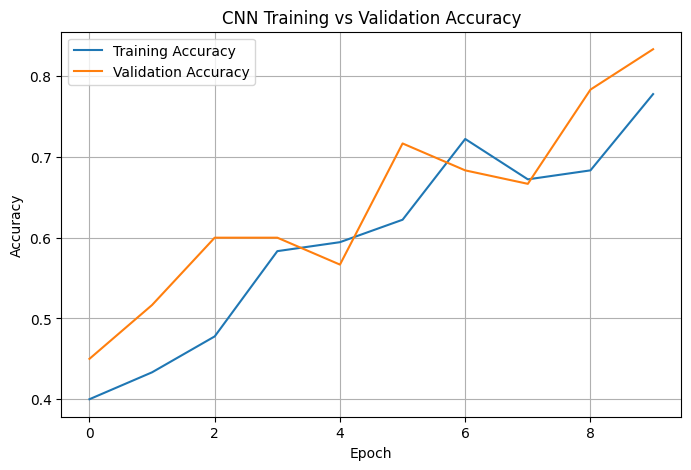

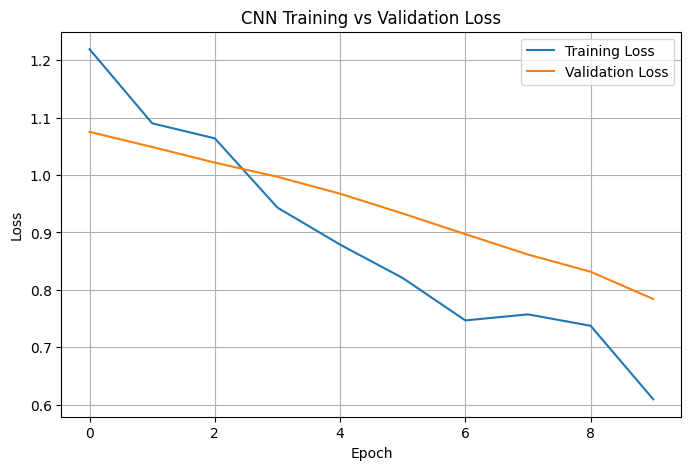

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history["train_acc"],
    label="Training Accuracy"
)

plt.plot(
    history["val_acc"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))

plt.plot(
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [12]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

model.eval()

with torch.no_grad():
    test_logits = model(X_test)
    test_predictions = test_logits.argmax(dim=1).numpy()

actual = y_test.numpy()

names = ["GPT", "Gemini", "Perplexity"]

print("CNN Test Accuracy:",
      accuracy_score(actual, test_predictions))

print("\nClassification Report:")
print(classification_report(
    actual,
    test_predictions,
    labels=[0, 1, 2],
    target_names=names,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    actual,
    test_predictions,
    labels=[0, 1, 2]
))

CNN Test Accuracy: 0.8166666666666667

Classification Report:
              precision    recall  f1-score   support

         GPT       0.89      0.80      0.84        20
      Gemini       0.82      0.90      0.86        20
  Perplexity       0.75      0.75      0.75        20

    accuracy                           0.82        60
   macro avg       0.82      0.82      0.82        60
weighted avg       0.82      0.82      0.82        60


Confusion Matrix:
[[16  1  3]
 [ 0 18  2]
 [ 2  3 15]]


In [17]:
import torch
import torch.nn as nn

class LLM_LSTM(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, 64, padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=64,
            hidden_size=64,
            batch_first=True
        )

        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(64, 3)

    def forward(self, x):
        lengths = (x != 0).sum(dim=1).clamp(min=1)

        embedded = self.embedding(x)

        packed = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, _) = self.lstm(packed)

        x = self.dropout(hidden[-1])

        return self.fc(x)


torch.manual_seed(42)

lstm_model = LLM_LSTM(len(vocab))

print(lstm_model)

LLM_LSTM(
  (embedding): Embedding(2264, 64, padding_idx=0)
  (lstm): LSTM(64, 64, batch_first=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=64, out_features=3, bias=True)
)


In [18]:
from torch.utils.data import TensorDataset, DataLoader

lstm_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=4,
    shuffle=True
)

lstm_optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

lstm_criterion = nn.CrossEntropyLoss()

lstm_history = []

for epoch in range(10):
    lstm_model.train()

    total_loss = 0
    correct = 0
    total = 0

    for texts, labels in lstm_loader:
        lstm_optimizer.zero_grad()

        outputs = lstm_model(texts)
        loss = lstm_criterion(outputs, labels)

        loss.backward()
        lstm_optimizer.step()

        total_loss += loss.item() * len(labels)
        correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        total += len(labels)

    train_acc = correct / total
    train_loss = total_loss / total

    lstm_model.eval()

    with torch.no_grad():
        val_outputs = lstm_model(X_val)
        val_loss = lstm_criterion(
            val_outputs, y_val
        ).item()

        val_acc = (
            val_outputs.argmax(dim=1) == y_val
        ).float().mean().item()

    lstm_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "validation_loss": val_loss,
        "validation_accuracy": val_acc
    })

    print(
        f"Epoch {epoch+1}/10 | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Acc: {val_acc:.2%} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

Epoch 1/10 | Train Acc: 36.11% | Val Acc: 43.33% | Train Loss: 1.1095 | Val Loss: 1.0826
Epoch 2/10 | Train Acc: 48.33% | Val Acc: 51.67% | Train Loss: 1.0624 | Val Loss: 1.0748
Epoch 3/10 | Train Acc: 61.67% | Val Acc: 51.67% | Train Loss: 1.0048 | Val Loss: 1.0641
Epoch 4/10 | Train Acc: 66.67% | Val Acc: 51.67% | Train Loss: 0.9517 | Val Loss: 1.0426
Epoch 5/10 | Train Acc: 78.89% | Val Acc: 58.33% | Train Loss: 0.8092 | Val Loss: 0.9736
Epoch 6/10 | Train Acc: 83.89% | Val Acc: 53.33% | Train Loss: 0.5653 | Val Loss: 0.9491
Epoch 7/10 | Train Acc: 90.00% | Val Acc: 61.67% | Train Loss: 0.4242 | Val Loss: 0.8376
Epoch 8/10 | Train Acc: 97.78% | Val Acc: 71.67% | Train Loss: 0.2382 | Val Loss: 0.7037
Epoch 9/10 | Train Acc: 99.44% | Val Acc: 73.33% | Train Loss: 0.1010 | Val Loss: 0.7588
Epoch 10/10 | Train Acc: 98.89% | Val Acc: 73.33% | Train Loss: 0.0792 | Val Loss: 0.7409


In [19]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

lstm_model.eval()

with torch.no_grad():
    outputs = lstm_model(X_val)
    lstm_predictions = outputs.argmax(dim=1).numpy()

actual = y_val.numpy()
names = ["GPT", "Gemini", "Perplexity"]

print("LSTM Validation Accuracy:",
      accuracy_score(actual, lstm_predictions))

print("\nClassification Report:")
print(classification_report(
    actual,
    lstm_predictions,
    labels=[0, 1, 2],
    target_names=names,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    actual,
    lstm_predictions,
    labels=[0, 1, 2]
))

LSTM Validation Accuracy: 0.7333333333333333

Classification Report:
              precision    recall  f1-score   support

         GPT       0.72      0.65      0.68        20
      Gemini       0.74      0.85      0.79        20
  Perplexity       0.74      0.70      0.72        20

    accuracy                           0.73        60
   macro avg       0.73      0.73      0.73        60
weighted avg       0.73      0.73      0.73        60


Confusion Matrix:
[[13  3  4]
 [ 2 17  1]
 [ 3  3 14]]


In [24]:
# Evaluate LSTM on the test dataset
lstm_model.eval()

with torch.no_grad():
    outputs = lstm_model(X_test)
    predictions = outputs.argmax(dim=1).numpy()

actual = y_test.numpy()

print("LSTM Test Accuracy:",
      accuracy_score(actual, predictions))

print("\nClassification Report:")
print(classification_report(
    actual,
    predictions,
    labels=[0, 1, 2],
    target_names=["GPT", "Gemini", "Perplexity"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    actual, predictions,
    labels=[0, 1, 2]
))


LSTM Test Accuracy: 0.6833333333333333

Classification Report:
              precision    recall  f1-score   support

         GPT       0.75      0.60      0.67        20
      Gemini       0.68      0.95      0.79        20
  Perplexity       0.62      0.50      0.56        20

    accuracy                           0.68        60
   macro avg       0.68      0.68      0.67        60
weighted avg       0.68      0.68      0.67        60


Confusion Matrix:
[[12  3  5]
 [ 0 19  1]
 [ 4  6 10]]


In [22]:
#RQ2

from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
import pandas as pd

# Three experimental configurations
experiments = {
    "Input Only": ["input"],
    "Output Only": ["output"],
    "Input + Output": ["input", "output"]
}

results = []

def get_text(data, columns):
    return data[columns].fillna("").agg(" ".join, axis=1)

for name, columns in experiments.items():

    X_train_text = get_text(train_df, columns)
    X_val_text = get_text(val_df, columns)
    X_test_text = get_text(test_df, columns)

    y_train_labels = train_df["llm_name"]
    y_val_labels = val_df["llm_name"]
    y_test_labels = test_df["llm_name"]

    classifier = make_pipeline(
        TfidfVectorizer(
            ngram_range=(1, 2),
            max_features=5000
        ),
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )

    classifier.fit(X_train_text, y_train_labels)

    val_predictions = classifier.predict(X_val_text)
    test_predictions = classifier.predict(X_test_text)

    results.append({
        "Experiment": name,
        "Validation Accuracy": accuracy_score(
            y_val_labels, val_predictions
        ),
        "Test Accuracy": accuracy_score(
            y_test_labels, test_predictions
        ),
        "Macro F1": f1_score(
            y_test_labels, test_predictions,
            average="macro"
        )
    })

    print(f"\n{name}")
    print(classification_report(
        y_test_labels, test_predictions,
        zero_division=0
    ))

results_df = pd.DataFrame(results)
display(results_df)



Input Only
              precision    recall  f1-score   support

         GPT       0.33      1.00      0.50        20
      Gemini       0.00      0.00      0.00        20
  Perplexity       0.00      0.00      0.00        20

    accuracy                           0.33        60
   macro avg       0.11      0.33      0.17        60
weighted avg       0.11      0.33      0.17        60


Output Only
              precision    recall  f1-score   support

         GPT       0.95      0.95      0.95        20
      Gemini       0.90      0.95      0.93        20
  Perplexity       0.95      0.90      0.92        20

    accuracy                           0.93        60
   macro avg       0.93      0.93      0.93        60
weighted avg       0.93      0.93      0.93        60


Input + Output
              precision    recall  f1-score   support

         GPT       0.86      0.95      0.90        20
      Gemini       0.90      0.90      0.90        20
  Perplexity       1.00      0.90 

,Experiment,Validation Accuracy,Test Accuracy,Macro F1
0,Input Only,0.333333,0.333333,0.166667
1,Output Only,0.950000,0.933333,0.933302
2,Input + Output,0.950000,0.916667,0.917377
